# Chapitre 3 - Lab : les index de PostgreSQL vus de l'intérieur

Ce lab confronte le cours à un vrai moteur : PostgreSQL 16, qui range ses tables dans un
**fichier de tas** et ses index dans des **B-trees** (cours 3 et 4). Nous allons :

1. mesurer un parcours séquentiel et lire un plan d'exécution (`EXPLAIN ANALYZE`) ;
2. inspecter la structure réelle d'un index B-tree (extension `pageinspect`) et observer
   le choix du plan selon la sélectivité ;
3. obtenir un **index-only scan** grâce à un index couvrant (`INCLUDE`) ;
4. mesurer le coût des index en écriture, en octets de **WAL** ;
5. observer la **fragmentation** après des suppressions et le rôle de `VACUUM` ;
6. construire un index **GIN** pour la recherche plein texte.

**Démarrer et arrêter les services** (depuis la racine du dépôt) :

```bash
docker compose -f docker/storage/compose.yml -p ddia_storage up -d     # démarrer
docker compose -f docker/storage/compose.yml -p ddia_storage down -v   # arrêter et effacer
```

PostgreSQL écoute sur le port **10432** de la machine (utilisateur, mot de passe et base :
`ddia` / `ddia` / `stockage`).

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg

from ddia import storage as S
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 120)

DSN = "host=localhost port=10432 user=ddia password=ddia dbname=stockage"
con = None
for essai in range(30):
    try:
        con = psycopg.connect(DSN, autocommit=True)
        break
    except psycopg.OperationalError:
        time.sleep(1)
assert con is not None, "PostgreSQL ne répond pas : avez-vous lancé docker compose up ?"
print(con.execute("SELECT version()").fetchone()[0][:60])


def q(sql, params=None):
    """Exécute une requête et renvoie toutes les lignes."""
    return con.execute(sql, params).fetchall()


def plan(sql):
    """Plan réel (EXPLAIN ANALYZE, BUFFERS) sous forme de texte."""
    return "\n".join(r[0] for r in q("EXPLAIN (ANALYZE, BUFFERS, TIMING OFF, SUMMARY OFF) " + sql))


def plan_json(sql):
    return q("EXPLAIN (ANALYZE, BUFFERS, FORMAT JSON) " + sql)[0][0][0]

PostgreSQL 16.14 (Debian 16.14-1.pgdg13+1) on x86_64-pc-linu


## 1. Une table et un parcours séquentiel (section *Data Structures That Power Your Database*)

On crée une table de commandes d'un million de lignes, générée côté serveur
(`generate_series`) avec une graine fixe. PostgreSQL range les lignes dans un **tas** :
des pages de 8 Kio, dans l'ordre d'insertion, sans index pour l'instant.

In [2]:
con.execute("DROP TABLE IF EXISTS commandes")
con.execute("""
CREATE TABLE commandes (
    id        bigint,
    client    int,
    statut    text,
    jour      int,
    montant   numeric(10, 2),
    adresse   text
)""")
con.execute("SELECT setseed(0.42)")
con.execute("""
INSERT INTO commandes
SELECT g,
       (100000 * random() ^ 2)::int,                       -- clients : quelques gros clients
       (ARRAY['livrée','livrée','livrée','expédiée','payée','annulée'])[1 + (random() * 5)::int],
       (random() * 364)::int,
       round((random() * 200)::numeric, 2),
       repeat('x', 80)
FROM generate_series(1, 1000000) AS g""")
con.execute("VACUUM ANALYZE commandes")
taille = q("SELECT pg_relation_size('commandes'), pg_size_pretty(pg_relation_size('commandes'))")[0]
print(f"table : {taille[1]}, soit {taille[0] // 8192} pages de 8 Kio")
print(plan("SELECT sum(montant) FROM commandes WHERE client = 4242"))

table : 137 MB, soit 17555 pages de 8 Kio
Finalize Aggregate  (cost=23763.58..23763.59 rows=1 width=32) (actual rows=1 loops=1)
  Buffers: shared hit=17555
  ->  Gather  (cost=23763.35..23763.56 rows=2 width=32) (actual rows=3 loops=1)
        Workers Planned: 2
        Workers Launched: 2
        Buffers: shared hit=17555
        ->  Partial Aggregate  (cost=22763.35..22763.36 rows=1 width=32) (actual rows=1 loops=3)
              Buffers: shared hit=17555
              ->  Parallel Seq Scan on commandes  (cost=0.00..22763.33 rows=7 width=6) (actual rows=10 loops=3)
                    Filter: (client = 4242)
                    Rows Removed by Filter: 333323
                    Buffers: shared hit=17555
Planning:
  Buffers: shared hit=29 read=2


Le plan montre un `Seq Scan` (parcours séquentiel, ici en parallèle) : PostgreSQL lit
**toutes** les pages du tas (`Buffers: shared hit=... read=...` : pages trouvées dans
son cache ou lues) pour trouver une poignée de lignes. C'est notre `db_get` du cours 1,
en plus rapide.

> **À retenir.** Sans index, toute requête sélective coûte un parcours de la table
> entière : le nombre de pages lues est la taille de la table.

## 2. Un index B-tree, vu de l'intérieur (section *B-Trees*)

Créons deux index B-tree, sur `id` (valeurs uniques) et sur `client` (beaucoup de
doublons), et inspectons-les avec l'extension `pageinspect` : `bt_metap` donne le niveau
de la racine (la hauteur moins un), `bt_multi_page_stats` le contenu de chaque page
(type `r` racine, `i` interne, `l` feuille).

In [3]:
con.execute("CREATE EXTENSION IF NOT EXISTS pageinspect")
con.execute("CREATE INDEX idx_id ON commandes(id)")
con.execute("CREATE INDEX idx_client ON commandes(client)")
lignes = []
for idx in ["idx_id", "idx_client"]:
    niveau = q(f"SELECT level FROM bt_metap('{idx}')")[0][0]
    for typ, n, items, taille_item, libre in q(f"""
            SELECT type, count(*), avg(live_items), avg(avg_item_size), avg(free_size)
            FROM bt_multi_page_stats('{idx}', 1, -1) GROUP BY type ORDER BY type DESC"""):
        lignes.append(dict(index=idx, hauteur=niveau + 1, type={"r": "racine", "i": "interne", "l": "feuille"}[typ],
                           pages=n, entrees_par_page=float(items), octets_par_entree=float(taille_item),
                           octets_libres=float(libre)))
pd.DataFrame(lignes).round(0)

,index,hauteur,type,pages,entrees_par_page,octets_par_entree,octets_libres
0,idx_id,3,racine,1,10.0,15.0,7956.0
1,idx_id,3,feuille,2733,367.0,16.0,810.0
2,idx_id,3,interne,10,274.0,15.0,2672.0
3,idx_client,3,racine,1,4.0,14.0,8076.0
4,idx_client,3,feuille,1128,90.0,119.0,775.0
5,idx_client,3,interne,4,283.0,15.0,2453.0


Un million d'entrées tiennent dans un arbre de **3 niveaux** : une racine, quelques
pages internes de plusieurs centaines d'entrées, et des feuilles. Pour `idx_id`, chaque
feuille contient environ 370 entrées de 16 octets (clé de 8 octets, identifiant de ligne
de 6 octets, alignement) et les pages sont presque pleines (l'index a été construit
d'un coup, en triant). Pour `idx_client`, les feuilles sont bien moins nombreuses
qu'attendu : depuis la version 13, PostgreSQL **déduplique** les entrées d'une même clé
en une seule entrée suivie de la **liste des identifiants de lignes**. C'est exactement
la première méthode d'index secondaire du cours 4 (une liste par valeur, comme une
postings list), d'où des entrées plus grosses mais beaucoup moins nombreuses.

**Hauteur selon la taille.** Construisons des index sur des tables de tailles
croissantes : la hauteur grandit d'un niveau à chaque facteur de quelques centaines.

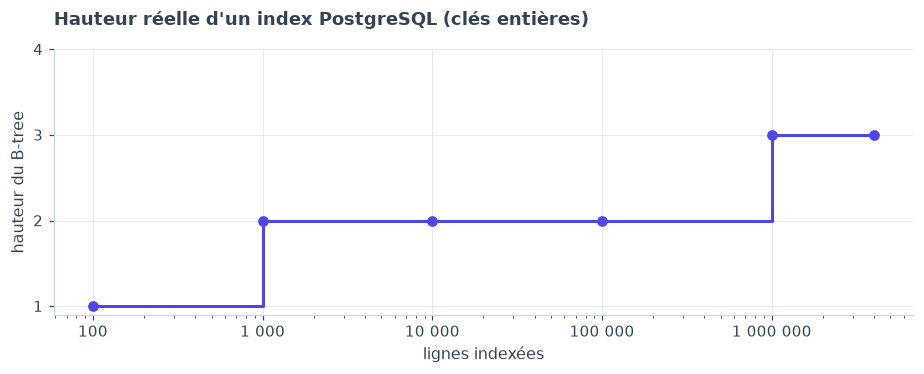

,lignes,hauteur,pages_index
0,100,1,2
1,1000,2,5
2,10000,2,30
3,100000,2,276
4,1000000,3,2745
5,4000000,3,10970


In [4]:
rows = []
for n in [100, 1_000, 10_000, 100_000, 1_000_000, 4_000_000]:
    con.execute("DROP TABLE IF EXISTS t_h")
    con.execute(f"CREATE TABLE t_h AS SELECT g AS k FROM generate_series(1, {n}) g")
    con.execute("CREATE INDEX t_h_k ON t_h(k)")
    lv = q("SELECT level FROM bt_metap('t_h_k')")[0][0]
    pages = q("SELECT pg_relation_size('t_h_k') / 8192")[0][0]
    rows.append(dict(lignes=n, hauteur=lv + 1, pages_index=pages))
con.execute("DROP TABLE t_h")
haut = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8.5, 3.5))
ax.step(haut.lignes, haut.hauteur, where="post", color=INDIGO, lw=2)
ax.plot(haut.lignes, haut.hauteur, "o", color=INDIGO)
ax.set_xscale("log"); S.plain_log_ticks(ax, "x")
ax.set_yticks(range(1, 5)); ax.set_xlabel("lignes indexées"); ax.set_ylabel("hauteur du B-tree")
ax.set_title("Hauteur réelle d'un index PostgreSQL (clés entières)")
plt.tight_layout(); plt.show()
haut

**Le choix du plan selon la sélectivité.** Le cours 4 prévoyait qu'un index secondaire
sur un tas ne bat un parcours séquentiel que pour des requêtes **sélectives**. Faisons
varier la fraction de lignes sélectionnées (par un intervalle de clients) et notons le
plan choisi par l'optimiseur et le nombre de pages touchées.

In [5]:
con.execute("CREATE INDEX idx_jour ON commandes(jour)")
con.execute("ANALYZE commandes")
rows = []
for jours in [1, 3, 10, 30, 90, 180, 365]:
    sql = f"SELECT sum(montant) FROM commandes WHERE jour < {jours}"
    pj = plan_json(sql)

    def noeuds(nd):
        yield nd
        for c in nd.get("Plans", []):
            yield from noeuds(c)

    types = [nd["Node Type"] for nd in noeuds(pj["Plan"])]
    principal = next(t for t in types if "Scan" in t)
    t0 = time.perf_counter()
    q(sql)
    rows.append(dict(fraction=jours / 365, plan=principal, pages=pj["Plan"].get("Shared Hit Blocks", 0)
                     + pj["Plan"].get("Shared Read Blocks", 0), ms=(time.perf_counter() - t0) * 1e3))
sel = pd.DataFrame(rows)
sel

,fraction,plan,pages,ms
0,0.003,Bitmap Heap Scan,1319,0.636
1,0.008,Bitmap Heap Scan,5765,2.249
2,0.027,Bitmap Heap Scan,13710,6.467
3,0.082,Bitmap Heap Scan,17498,15.324
4,0.247,Bitmap Heap Scan,17770,29.863
5,0.493,Seq Scan,17555,23.727
6,1.000,Seq Scan,17555,26.491


Pour les requêtes sélectives, l'optimiseur choisit l'index, sous la forme d'un `Bitmap
Index Scan` suivi d'un `Bitmap Heap Scan` : il construit d'abord un bitmap des pages du
tas à visiter, puis les lit **dans l'ordre physique**, chacune une seule fois. Cette
astuce transforme des lectures aléatoires en lectures presque séquentielles, et repousse
loin le point de bascule : ici, le `Seq Scan` ne revient que vers la moitié des lignes.
Mais la colonne `pages` montre la limite prévue par le cours 4 : avec environ 57 lignes
par page, dès quelques pourcents de lignes sélectionnées, presque **toutes** les pages
du tas contiennent au moins une ligne voulue
($1 - (1 - s)^{57}$ vaut déjà 80 % pour $s = 3\,\%$), et l'index ne fait plus gagner
de pages. (Le seuil exact dépend des statistiques et des paramètres `random_page_cost`
et `seq_page_cost`.)

> **À retenir.** Un vrai B-tree PostgreSQL a 3 ou 4 niveaux pour des millions de
> lignes. L'optimiseur n'utilise un index secondaire que si la requête est assez
> sélective : sinon, le parcours séquentiel du tas est moins cher.